In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
import requests

In [121]:
import json
from datetime import datetime

URL = "https://www.treasurydirect.gov/TA_WS/securities/search"

retrieved_at = datetime.now().isoformat()
response = requests.get(URL, params={"type": "Note"}, timeout=30)
response.raise_for_status()

data = response.json()   

with open("treasury_response.json", "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)

print(f"Retrieved at: {retrieved_at}\nNumber of records: {len(data)}")

Retrieved at: 2026-10-10T23:13:57.259210
Number of records: 1972


In [163]:
today = pd.Timestamp.today().normalize()
valid_notes = []

for r in data:
    issue_date = pd.to_datetime(
        r.get("issueDate"),
        errors="coerce"
    )

    if (
        r.get("securityTerm") == "5-Year"
        and pd.notna(issue_date)
        and issue_date <= today
    ):
        valid_notes.append((issue_date, r))

if not valid_notes:
    raise ValueError(
        "No 5-Year note with a valid issue date was found."
    )

valid_notes.sort(key=lambda x: x[0], reverse=True)

issue_date, bond = valid_notes[0]

print(f"Issue Date: {issue_date.date()} | CUSIP: {bond.get('cusip')}")

Issue Date: 2026-09-30 | CUSIP: 91282CRN3


In [63]:
# Select the most recent issued 5-Year Treasury Note
today = pd.Timestamp.today()

five_year_notes = sorted(
    (r for r in data
     if r.get("securityType") == "Note"
     and r.get("securityTerm") == "5-Year"
     and pd.Timestamp(r["issueDate"]) <= today),
    key=lambda r: r["issueDate"],
    reverse=True,
)

print("Number of 5-Year Notes:", len(five_year_notes))

bond = five_year_notes[0]

bond_data = pd.DataFrame([{
    "CUSIP": bond["cusip"],
    "Issue Date": pd.to_datetime(bond["issueDate"]),
    "Maturity Date": pd.to_datetime(bond["maturityDate"]),
    "Coupon Rate": float(bond["interestRate"]) / 100,
    "Auction Price": float(bond["pricePer100"]),
    "Median Yield": float(bond["averageMedianYield"]) / 100,
    "High Yield": float(bond["highYield"]) / 100,
    "Payment Frequency": bond["interestPaymentFrequency"],
    "Security Term": bond["securityTerm"],
}])

bond_data

Number of 5-Year Notes: 383


,CUSIP,Issue Date,Maturity Date,Coupon Rate,Auction Price,Median Yield,High Yield,Payment Frequency,Security Term
0,91282CRN3,2026-09-30,2031-09-30,0.05,99.855714,0.0495,0.05033,Semi-Annual,5-Year


In [125]:
# Bond parameters
FACE_VALUE = 1000

COUPON_RATE = float(bond["interestRate"]) / 100

frequency_map = {
    "Annual": 1,
    "Semi-Annual": 2,
    "Quarterly": 4,
    "Monthly": 12,
}

payment_frequency = bond.get("interestPaymentFrequency")

if payment_frequency not in frequency_map:
    raise ValueError(
        f"Unknown payment frequency: {payment_frequency}"
    )

FREQUENCY = frequency_map[payment_frequency]

COUPON_PAYMENT = (
    FACE_VALUE
    * COUPON_RATE
    / FREQUENCY
)

print(
    f"Face Value: ${FACE_VALUE:,.2f} | "
    f"Annual Coupon Rate: {COUPON_RATE:.2%} | "
    f"Coupon Payment: ${COUPON_PAYMENT:,.2f} | "
    f"Payment Frequency: {FREQUENCY} times per year"
)

Face Value: $1,000.00 | Annual Coupon Rate: 5.00% | Coupon Payment: $25.00 | Payment Frequency: 2 times per year


<div style="text-align: left;">

###  Model Assumptions

- **Settlement on the issue date** (2026-09-30): accrued interest is zero, so the clean price equals the dirty price.
- Cash flows are modeled as **10 equal semi-annual periods**. In practice, the first coupon is paid on 2027-03-31 (end-of-month rule) and Treasury uses Actual/Actual day count; the effect of this difference is negligible.
- Yields are **bond-equivalent yields with semi-annual compounding** (`y/2` per period), following Treasury market convention.

</div>

In [131]:
# Build the bond cash flow schedule

MATURITY_YEARS = round((pd.Timestamp(bond["maturityDate"]) - pd.Timestamp(bond["issueDate"])).days / 365.25)
NUM_PERIODS = MATURITY_YEARS * FREQUENCY

cash_flows = pd.DataFrame({
    "Period": range(1, NUM_PERIODS + 1)
})

cash_flows["Year"] = cash_flows["Period"] / FREQUENCY
cash_flows["Coupon"] = COUPON_PAYMENT
cash_flows["Principal"] = 0.0

# Principal is repaid at maturity
cash_flows.loc[cash_flows["Period"] == NUM_PERIODS, "Principal"] = FACE_VALUE

cash_flows["Total Cash Flow"] = (
    cash_flows["Coupon"] + cash_flows["Principal"]
)

cash_flows

,Period,Year,Coupon,Principal,Total Cash Flow
0,1,0.5,25.0,0.0,25.0
1,2,1.0,25.0,0.0,25.0
2,3,1.5,25.0,0.0,25.0
3,4,2.0,25.0,0.0,25.0
4,5,2.5,25.0,0.0,25.0
5,6,3.0,25.0,0.0,25.0
6,7,3.5,25.0,0.0,25.0
7,8,4.0,25.0,0.0,25.0
8,9,4.5,25.0,0.0,25.0
9,10,5.0,25.0,1000.0,1025.0


In [133]:
YIELD_TO_MATURITY = float(bond["averageMedianYield"]) / 100
theoretical_price = (
    cash_flows["Total Cash Flow"] / (1 + YIELD_TO_MATURITY / FREQUENCY) ** cash_flows["Period"]
).sum()
print(f"Price at Median Yield ({YIELD_TO_MATURITY:.4%}): ${theoretical_price:,.4f}")

Price at Median Yield (4.9500%): $1,002.1908


In [135]:
from scipy.optimize import brentq

AUCTION_PRICE = float(bond["pricePer100"]) * FACE_VALUE / 100
HIGH_YIELD = float(bond["highYield"]) / 100
MEDIAN_YIELD = float(bond["averageMedianYield"]) / 100

def bond_price(yield_rate):
    periodic_rate = yield_rate / FREQUENCY
    discount_factors = 1 / (1 + periodic_rate) ** cash_flows["Period"]
    return (cash_flows["Total Cash Flow"] * discount_factors).sum()

def price_difference(yield_rate):
    return bond_price(yield_rate) - AUCTION_PRICE

implied_ytm = brentq(price_difference, 0.0001, 0.20)

print(
    f"Auction Price: ${AUCTION_PRICE:,.4f}\n"
    f"Implied YTM:   {implied_ytm:.4%}\n"
    f"High Yield:    {HIGH_YIELD:.4%}\n"
    f"Median Yield:  {MEDIAN_YIELD:.4%}"
)

Auction Price: $998.5571
Implied YTM:   5.0330%
High Yield:    5.0330%
Median Yield:  4.9500%


In [143]:
MEDIAN_YIELD = float(bond["averageMedianYield"]) / 100
HIGH_YIELD = float(bond["highYield"]) / 100

def price_from_yield(yield_rate):
    return (
        cash_flows["Total Cash Flow"]
        / (
            1 + yield_rate / FREQUENCY
        ) ** cash_flows["Period"]
    ).sum()

median_price = price_from_yield(MEDIAN_YIELD)
high_price = price_from_yield(HIGH_YIELD)

auction_price = (
    float(bond["pricePer100"])
    / 100
    * FACE_VALUE
)

print(
    f"Median Yield: {MEDIAN_YIELD:.4%}\n"
    f"Price at Median Yield: ${median_price:,.4f}\n"
    f"High Yield: {HIGH_YIELD:.4%}\n"
    f"Price at High Yield: ${high_price:,.4f}\n"
    f"Auction Price: ${AUCTION_PRICE:,.4f}"
)


Median Yield: 4.9500%
Price at Median Yield: $1,002.1908
High Yield: 5.0330%
Price at High Yield: $998.5571
Auction Price: $998.5571


<div style="text-align: left;">

### Why Is the Implied YTM 5.033% Instead of 4.95%?

U.S. Treasury securities are sold through a **single-price auction**: all successful bidders pay the same price, which corresponds to the **High Yield (stop-out yield)**.

| Measure | Value | Explanation |
|:---|---:|:---|
| Median Yield | 4.95% | Median yield of the accepted bids, weighted by amount; a descriptive statistic |
| **High Yield** | **5.033%** | The stop-out yield, which determines the auction price |

Therefore, the auction price of **99.855714 per $100 of face value** corresponds to a yield of **5.033%**, and the implied YTM calculated from this price matches the High Yield.

The price of **$1,002.19**, calculated using the Median Yield of 4.95%, is a hypothetical value; it is not the price paid in the auction. The code above confirms this: pricing the bond at the High Yield reproduces the auction price exactly.

</div>

In [145]:
MARKET_PRICE = float(bond["pricePer100"]) / 100 * FACE_VALUE

cash_flows["PV"] = (
    cash_flows["Total Cash Flow"]
    / (1 + implied_ytm / FREQUENCY) ** cash_flows["Period"]
)

cash_flows["Time Weight"] = cash_flows["Year"] * cash_flows["PV"]

macaulay_duration = (
    cash_flows["Time Weight"].sum()
    / cash_flows["PV"].sum()
)

print(
    f"Market Price: ${MARKET_PRICE:,.4f}\n"
    f"PV of Cash Flows: ${cash_flows['PV'].sum():,.4f}\n"
    f"Macaulay Duration: {macaulay_duration:.4f} years"
)


Market Price: $998.5571
PV of Cash Flows: $998.5571
Macaulay Duration: 4.4850 years


In [149]:
# Calculate Modified Duration

modified_duration = (
    macaulay_duration
    / (1 + implied_ytm / FREQUENCY)
)

print(
    f"Macaulay Duration: {macaulay_duration:.4f} years\n"
    f"Modified Duration: {modified_duration:.4f} years"
)

Macaulay Duration: 4.4850 years
Modified Duration: 4.3749 years


In [151]:
# Estimate price sensitivity using Modified Duration

YIELD_CHANGE = 0.01  # +1 percentage point

estimated_price_change_pct = (
    -modified_duration * YIELD_CHANGE
)

estimated_new_price = (
    MARKET_PRICE * (1 + estimated_price_change_pct)
)

print(
    f"Initial Auction Price: ${AUCTION_PRICE:,.4f}\n"
    f"Yield Change: +{YIELD_CHANGE:.2%}\n"
    f"Estimated Price Change: {estimated_price_change_pct:.4%}\n"
    f"Estimated New Price: ${estimated_new_price:,.4f}"
)

Initial Auction Price: $998.5571
Yield Change: +1.00%
Estimated Price Change: -4.3749%
Estimated New Price: $954.8714


In [153]:
# Calculate the exact bond price after a +1% yield shock

SHOCKED_YTM = implied_ytm + YIELD_CHANGE

exact_shocked_price = bond_price(SHOCKED_YTM)

exact_price_change_pct = (
    (exact_shocked_price / MARKET_PRICE) - 1
)

duration_estimate_error = (
    estimated_new_price - exact_shocked_price
)

print(
    f"Original YTM: {implied_ytm:.4%}\n"
    f"Shocked YTM: {SHOCKED_YTM:.4%}\n"
    f"Original Price: ${AUCTION_PRICE:,.4f}\n"
    f"Exact New Price: ${exact_shocked_price:,.4f}\n"
    f"Exact Price Change: {exact_price_change_pct:.4%}\n"
    f"Duration Estimate: ${estimated_new_price:,.4f}\n"
    f"Duration Estimation Error: {duration_estimate_error:+,.4f} $"
)

Original YTM: 5.0330%
Shocked YTM: 6.0330%
Original Price: $998.5571
Exact New Price: $955.9786
Exact Price Change: -4.2640%
Duration Estimate: $954.8714
Duration Estimation Error: -1.1072 $


In [155]:
def bond_convexity(yield_rate):
    r = yield_rate / FREQUENCY
    t = cash_flows["Period"]
    cf = cash_flows["Total Cash Flow"]
    return (cf * t * (t + 1) / (1 + r) ** (t + 2)).sum() / (FREQUENCY**2 * bond_price(yield_rate))

CONVEXITY = bond_convexity(implied_ytm)
print(f"Bond Convexity: {CONVEXITY:.4f}")

Bond Convexity: 22.6021


In [157]:
# Estimate bond price using Duration + Convexity

duration_effect = -modified_duration * YIELD_CHANGE

convexity_effect = (
    0.5 * CONVEXITY * (YIELD_CHANGE ** 2)
)

estimated_change_pct_dc = (
    duration_effect + convexity_effect
)

estimated_price_dc = (
    MARKET_PRICE * (1 + estimated_change_pct_dc)
)

print(
    f"Duration Effect: {duration_effect:.4%}\n"
    f"Convexity Effect: {convexity_effect:.4%}\n"
    f"Estimated Price Change: {estimated_change_pct_dc:.4%}\n"
    f"Duration + Convexity Price: ${estimated_price_dc:,.4f}\n"
    f"Exact New Price: ${exact_shocked_price:,.4f}"
)

Duration Effect: -4.3749%
Convexity Effect: 0.1130%
Estimated Price Change: -4.2619%
Duration + Convexity Price: $955.9998
Exact New Price: $955.9786


In [159]:
shocks = [-0.01, 0.005, 0.01, 0.02, 0.03]
rows = []

for dy in shocks:
    exact = bond_price(implied_ytm + dy)
    dur_only = AUCTION_PRICE * (1 - modified_duration * dy)
    dur_conv = AUCTION_PRICE * (1 - modified_duration * dy + 0.5 * CONVEXITY * dy**2)
    rows.append({
        "Shock (bp)": int(dy * 10000),
        "Exact Price": exact,
        "Duration Error": dur_only - exact,
        "Duration+Convexity Error": dur_conv - exact,
    })

error_table = pd.DataFrame(rows)
error_table

,Shock (bp),Exact Price,Duration Error,Duration+Convexity Error
0,-100,1043.393329,-1.150419,-0.021944
1,50,976.993695,-0.279440,0.002679
2,100,955.978579,-1.107209,0.021267
3,200,915.531970,-4.346369,0.167532
4,300,877.099236,-9.599405,0.556874


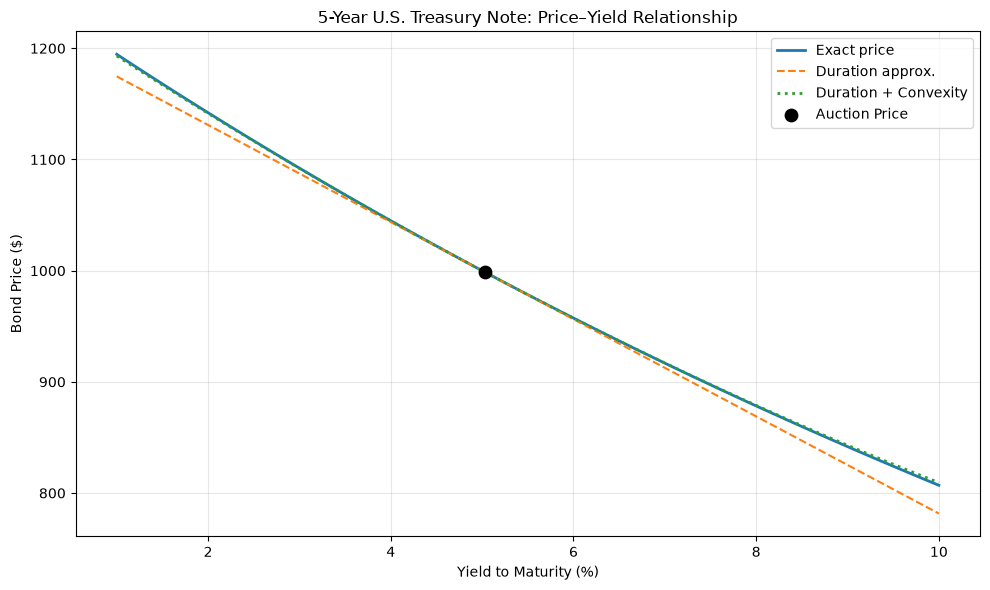

In [165]:
yield_range = np.linspace(0.01, 0.10, 100)
prices = [bond_price(y) for y in yield_range]

dy = yield_range - implied_ytm
tangent = AUCTION_PRICE * (1 - modified_duration * dy)
second_order = AUCTION_PRICE * (1 - modified_duration * dy + 0.5 * CONVEXITY * dy**2)

plt.figure(figsize=(10, 6))
plt.plot(yield_range * 100, prices, linewidth=2, label="Exact price")
plt.plot(yield_range * 100, tangent, "--", label="Duration approx.")
plt.plot(yield_range * 100, second_order, ":", linewidth=2, label="Duration + Convexity")
plt.scatter(implied_ytm * 100, AUCTION_PRICE, s=80, zorder=5, color="black", label="Auction Price")
plt.xlabel("Yield to Maturity (%)")
plt.ylabel("Bond Price ($)")
plt.title("5-Year U.S. Treasury Note: Price–Yield Relationship")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

<div style="text-align: left;">

## Conclusion

This project valued a **5-Year U.S. Treasury Note** using real auction data retrieved from the **U.S. TreasuryDirect API** (on 2026-10-10) and analyzed its exposure to interest-rate risk. The bond has a **\$1,000 face value**, a **5.00% annual coupon rate**, and **semi-annual coupon payments**.

### Key Results

| Metric            |           Result |
| :---------------- | ---------------: |
| Auction Price     |    **\$998.5571** |
| Implied YTM       |      **5.0330%** |
| Macaulay Duration | **4.4850 years** |
| Modified Duration | **4.3749 years** |
| Convexity         | **22.6021 years²** |

The auction price corresponds to the **High Yield (5.033%)**, not the Median Yield (4.95%), because Treasury auctions are single-price.

To evaluate interest-rate sensitivity, a **100-basis-point increase in YTM** was assumed, from **5.0330% to 6.0330%**. The Duration-only approach estimated a **4.3749% decline in price**, giving an estimated price of **\$954.8714**, compared with the exact price of **\$955.9786** (an error of \$1.1072).

When Convexity was added to Duration, the estimated price became **\$955.9998**, reducing the error to about **\$0.02**.

> **Overall, Modified Duration is a useful first-order measure of a bond's price sensitivity to interest-rate changes, and adding Convexity captures the curvature of the price–yield relationship. For small to moderate yield changes, the Duration + Convexity approximation is very close to the exact price; for larger shocks, the errors of both approximations grow (see the error table above), and direct repricing is more reliable.**

</div>